``` Data Ingestion, Data preprocessing, Feature Engineering```

In [1]:
#Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay,f1_score,precision_score,recall_score
#Load the dataset
df=pd.read_csv("/content/creditcard.csv")
#First five values
df.head()
#0----> Legitemate Trasnsaction
#1----> Fraudulent Transaction
#Dataset is highly unbalanced
df["Class"].value_counts()
#Seperating for analysis
legit=df[df.Class==0]
fraud=df[df.Class==1]
#Statistics of the amount
legit.Amount.describe()
fraud.Amount.describe()
#Compare the values for both transactions
df.groupby('Class').mean()
#Under-Sampling
#Build a dataset containing similar no of legit and fraudulent
legit_sample=legit.sample(n=500)
print(legit_sample.shape)
#Concatenating Dataframe
new_df=pd.concat([legit_sample,fraud],axis=0)
new_df.head()
#Seperate features and labels
X=new_df.drop(columns='Class',axis=1)
y=new_df['Class']
#Train test split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=2)

(500, 31)


``` Logistic Regression ```

Accuracy on train data out of 1: 0.9432534678436317
==== Performance on train data ====
F1 score: 0.9410222804718218
Recall: 0.9134860050890585
Precision: 0.9702702702702702
==== Performance on test data ====
Accuracy: 0.9447236180904522
F1 score: 0.9417989417989417
Recall: 0.898989898989899
Precision: 0.9888888888888889


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


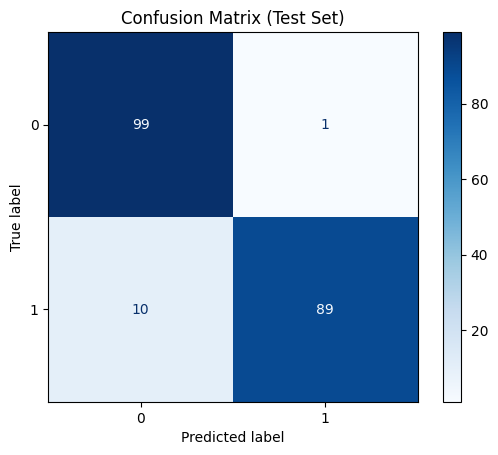

In [2]:
#Model--->Logistic Regression Model
model=LogisticRegression(C=10)
#Fit Model
model.fit(X_train,y_train)
#Predict based on train data
y_train_predict=model.predict(X_train)
# Find accuracy on train data
train_accuracy=accuracy_score(y_train,y_train_predict)
print("Accuracy on train data out of 1:",train_accuracy)
# Find F1 score, recall, precision
f1=f1_score(y_train,y_train_predict)
recall=recall_score(y_train,y_train_predict)
precision=precision_score(y_train,y_train_predict)
print("==== Performance on train data ====")
print("F1 score:",f1)
print("Recall:",recall)
print("Precision:",precision)
#Predict based on test data
y_test_predict=model.predict(X_test)
#Find accuracy,F1 score, precision, recall
test_accuracy=accuracy_score(y_test,y_test_predict)
test_f1_score=f1_score(y_test,y_test_predict)
test_recall=recall_score(y_test,y_test_predict)
test_precision=precision_score(y_test,y_test_predict)
# Find test accuracy
print("==== Performance on test data ====")
print("Accuracy:",test_accuracy)
print("F1 score:",test_f1_score)
print("Recall:",test_recall)
print("Precision:",test_precision)
# Build a confusion matrix
cm=confusion_matrix(y_test,y_test_predict)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test Set)")
plt.show()

``` Random Forest Classifier```

Accuracy on train data out of 1: 1.0
==== Performance on train data ====
F1 score: 1.0
Recall: 1.0
Precision: 1.0
==== Performance on test data ====
Accuracy: 0.9195979899497487
F1 score: 0.9157894736842105
Recall: 0.8787878787878788
Precision: 0.9560439560439561


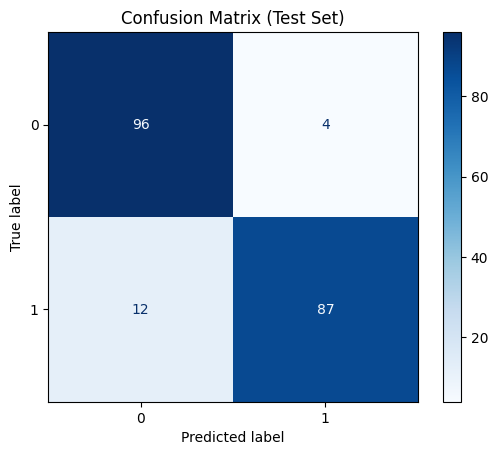

In [3]:
from sklearn.ensemble import RandomForestClassifier
#Model--->Random forest classifier Model
model_rf=RandomForestClassifier(n_estimators=100,random_state=2)
#Fit Model
model_rf.fit(X_train,y_train)
#Predict based on train data
y_train_predict=model_rf.predict(X_train)
# Find accuracy on train data
train_accuracy=accuracy_score(y_train,y_train_predict)
print("Accuracy on train data out of 1:",train_accuracy)
# Find F1 score, recall, precision
f1=f1_score(y_train,y_train_predict)
recall=recall_score(y_train,y_train_predict)
precision=precision_score(y_train,y_train_predict)
print("==== Performance on train data ====")
print("F1 score:",f1)
print("Recall:",recall)
print("Precision:",precision)
#Predict based on test data
y_test_predict=model_rf.predict(X_test)
#Find accuracy,F1 score, precision, recall
test_accuracy=accuracy_score(y_test,y_test_predict)
test_f1_score=f1_score(y_test,y_test_predict)
test_recall=recall_score(y_test,y_test_predict)
test_precision=precision_score(y_test,y_test_predict)
# Find test accuracy
print("==== Performance on test data ====")
print("Accuracy:",test_accuracy)
print("F1 score:",test_f1_score)
print("Recall:",test_recall)
print("Precision:",test_precision)
# Build a confusion matrix
cm=confusion_matrix(y_test,y_test_predict)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test Set)")
plt.show()

``` Support Vector Machine ```


Accuracy on train data out of 1: 0.9558638083228247
==== Performance on train data ====
F1 score: 0.9536423841059603
Recall: 0.916030534351145
Precision: 0.994475138121547
==== Performance on test data ====
Accuracy: 0.914572864321608
F1 score: 0.9090909090909091
Recall: 0.8585858585858586
Precision: 0.9659090909090909


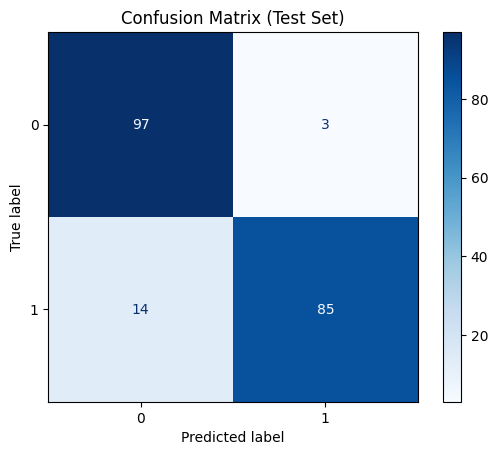

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
#Model--->Random forest classifier Model
model_svc=make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, random_state=2))
#Fit Model
model_svc.fit(X_train,y_train)
#Predict based on train data
y_train_predict=model_svc.predict(X_train)
# Find accuracy on train data
train_accuracy=accuracy_score(y_train,y_train_predict)
print("Accuracy on train data out of 1:",train_accuracy)
# Find F1 score, recall, precision
f1=f1_score(y_train,y_train_predict)
recall=recall_score(y_train,y_train_predict)
precision=precision_score(y_train,y_train_predict)
print("==== Performance on train data ====")
print("F1 score:",f1)
print("Recall:",recall)
print("Precision:",precision)
#Predict based on test data
y_test_predict=model_svc.predict(X_test)
#Find accuracy,F1 score, precision, recall
test_accuracy=accuracy_score(y_test,y_test_predict)
test_f1_score=f1_score(y_test,y_test_predict)
test_recall=recall_score(y_test,y_test_predict)
test_precision=precision_score(y_test,y_test_predict)
# Find test accuracy
print("==== Performance on test data ====")
print("Accuracy:",test_accuracy)
print("F1 score:",test_f1_score)
print("Recall:",test_recall)
print("Precision:",test_precision)
# Build a confusion matrix
cm=confusion_matrix(y_test,y_test_predict)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test Set)")
plt.show()